# MSC barycenter evaluation & sparsification

Load a **complete** (pre-threshold) barycenter bundle saved by `msc_barycenter_shortestpath.ipynb`, then:

1. Threshold edges at several `EDGE_FRACTION_PCT` values and score PFGW quality vs a seed baseline.
2. Attribute-alignment diagnostics under significant couplings.
3. Edge-density NMS sparsification of a chosen thresholded graph.

Shared helpers: `lib/msc_barycenter_eval.py`, `lib/msc_barycenter_threshold.py`, `lib/msc_plotting.py`, `lib/graph_sparsify.py`, `lib/barycenter_io.py`.


In [5]:
# Imports
import importlib
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

import lib.barycenter_io as barycenter_io
import lib.msc_barycenter_eval as msc_barycenter_eval
import lib.msc_barycenter_threshold as msc_barycenter_threshold
import lib.msc_plotting as msc_plotting
import lib.graph_sparsify as graph_sparsify

importlib.reload(barycenter_io)
importlib.reload(msc_barycenter_threshold)
importlib.reload(msc_barycenter_eval)
importlib.reload(msc_plotting)
importlib.reload(graph_sparsify)

from lib.barycenter_io import (
    load_barycenter_bundle,
    default_barycenter_outdir,
    resolve_eval_seed,
)
from lib.msc_barycenter_eval import (
    evaluate_seed_network,
    evaluate_thresholded_barycenter,
    attribute_alignment_for_eval_results,
    summarize_attribute_alignment_distributions,
    plot_attribute_alignment_boxplots,
)
from lib.msc_barycenter_threshold import build_thresholded_barycenter_graph
from lib.msc_plotting import draw_barycenter_thresholded_complete, set_barycenter_axes_limits
from lib.graph_sparsify import (
    SparsifyConfig,
    sparsify_graph,
    draw_sparsify_comparison,
    node_positions_from_graph,
)


## Load saved barycenter bundle

Set `BARYCENTER_OUTDIR` to the folder written by the main notebook (`results/barycenters/latest` by default).

The bundle records whether the seed was **in-set** (`exclude_seed=False`, seed is one of the PFGW inputs) or **out-of-set** (`exclude_seed=True`, seed stored under `seed/` and omitted from the barycenter input family). Loading resolves this automatically for the quality baseline.


In [6]:
BARYCENTER_OUTDIR = default_barycenter_outdir(run_name="latest")
bundle = load_barycenter_bundle(BARYCENTER_OUTDIR)
meta = bundle["meta"]

C_center = bundle["C_center"]
X_center = bundle["X_center"]
p = bundle["p"]
# Barycenter input family only (seed omitted when exclude_seed was True)
Cs = bundle["Cs"]
Ys = bundle["Ys"]
ps = bundle["ps"]
lambdas = bundle["lambdas"]
Ts = bundle["Ts"]
nodes_list = bundle["nodes_list"]
Gs = bundle["Gs"]
G_complete = bundle["G_complete"]
G_center = bundle["G_mst"]
mesh_ids = bundle["mesh_ids"]

# In-set vs out-of-set seed used as PFGW quality baseline
seed_info = resolve_eval_seed(bundle)
exclude_seed = seed_info["exclude_seed"]
seed_graph_id = seed_info["seed_graph_id"]
SEED_IDX = seed_info["seed_idx"]  # None when out-of-set
C_seed = seed_info["C_seed"]
Y_seed = seed_info["Y_seed"]
p_seed = seed_info["p_seed"]
seed_mesh_id = seed_info["seed_mesh_id"]
seed_label = seed_info["seed_label"]

# Unpack meta used by threshold / eval helpers
min_x, max_x = meta["min_x"], meta["max_x"]
min_y, max_y = meta["min_y"], meta["max_y"]
min_z, max_z = meta["min_z"], meta["max_z"]
domain_size = meta["domain_size"]
min_scalar = meta["min_scalar"]
max_scalar = meta["max_scalar"]
scalar_range = meta["scalar_range"]
MSC_TYPE_ORDER = list(meta["MSC_TYPE_ORDER"])
type_to_idx = {t: i for i, t in enumerate(MSC_TYPE_ORDER)}
n_types = len(MSC_TYPE_ORDER)
type_scale = float(meta.get("type_scale", 1.0 / np.sqrt(2)))

relation_kind = meta.get("relation_kind", "shortestpath")
relation_rescale = float(meta.get("relation_rescale", 1.0))
relation_offset = float(meta.get("relation_offset", 0.0))
sp_weighted = bool(meta.get("sp_weighted", True))
laplacian_base = meta.get("laplacian_base", "adjacency")
laplacian_normalization = meta.get("laplacian_normalization", "none")
tau = float(meta.get("tau", 1.0))
sp_affinity = meta.get("sp_affinity", "exp")
sp_sigma = meta.get("sp_sigma", None)
alpha_fgw = float(meta.get("alpha_fgw", 0.5))
gw_restarts = int(meta.get("gw_restarts", 1))
gw_seed_start = int(meta.get("gw_seed_start", 0))
max_iter = int(meta.get("max_iter", 200))
Lambda_list = meta.get("Lambda_list")
if Lambda_list is None or len(Lambda_list) != len(Cs):
    lp = meta.get("lambda_penalty", 0.05)
    Lambda_list = [lp] * len(Cs)
if len(lambdas) != len(Cs):
    lambdas = np.ones(len(Cs), dtype=float) / max(len(Cs), 1)

print(f"Loaded bundle from {Path(BARYCENTER_OUTDIR).resolve()}")
print(f"C_center {C_center.shape}, X_center {X_center.shape}, n_inputs={len(Cs)}")
print(f"Seed baseline: {seed_label} (exclude_seed={exclude_seed})")
if G_complete is not None:
    print(
        f"G_complete: {G_complete.number_of_nodes()} nodes, "
        f"{G_complete.number_of_edges()} edges (pre-threshold)"
    )


Loaded bundle from C:\Users\mingz\desktop\MSCBarycenter\results\barycenters\latest
C_center (407, 407), X_center (407, 8), n_inputs=9
Seed baseline: out-of-set seed (orig idx 0, mesh 0) (exclude_seed=True)
G_complete: 407 nodes, 82621 edges (pre-threshold)


## Evaluation: thresholded barycenter quality

Score how well a **thresholded** barycenter network explains the input family, relative to a trivial seed baseline (in-set or out-of-set, as recorded in the bundle).

Quality = (sum of PFGW costs of thresholded barycenter) / (sum of PFGW costs of seed). Values **< 1** improve on the seed.


Seed network: out-of-set seed (orig idx 0, mesh 0), PFGW sum = 0.00221607

EDGE_FRACTION_PCT=4: kept 3305/82621 edges, components=1, bary_cost=0.00164706, seed_cost=0.00221607, quality=0.743235
EDGE_FRACTION_PCT=5: kept 4132/82621 edges, components=1, bary_cost=0.00163665, seed_cost=0.00221607, quality=0.738538
EDGE_FRACTION_PCT=6: kept 4958/82621 edges, components=1, bary_cost=0.00162885, seed_cost=0.00221607, quality=0.735017
EDGE_FRACTION_PCT=7: kept 5784/82621 edges, components=1, bary_cost=0.00162487, seed_cost=0.00221607, quality=0.733223
EDGE_FRACTION_PCT=8: kept 6610/82621 edges, components=1, bary_cost=0.00162278, seed_cost=0.00221607, quality=0.73228
EDGE_FRACTION_PCT=9: kept 7436/82621 edges, components=1, bary_cost=0.00162214, seed_cost=0.00221607, quality=0.731991
EDGE_FRACTION_PCT=10: kept 8263/82621 edges, components=1, bary_cost=0.00162183, seed_cost=0.00221607, quality=0.73185

--- Summary ---
     pct      edges   comp      bary_cost    quality
     4.0       3305    

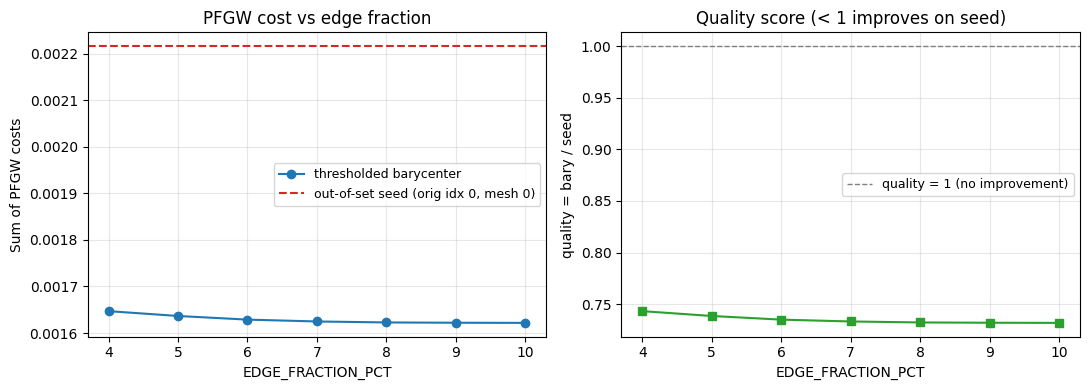

: 

In [ ]:
# Evaluation sweep over edge fractions
# Seed baseline comes from the loaded bundle (in-set index or out-of-set seed/).

EDGE_FRACTION_PCTS = [4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]
RECOMPUTE_X = False

eval_kwargs = dict(
    C_center=C_center,
    X_center=X_center,
    p_eval=p,
    Cs=Cs,
    Ys=Ys,
    ps=ps,
    Lambda_list=Lambda_list,
    lambdas=lambdas,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    min_scalar=min_scalar,
    scalar_range=scalar_range,
    msc_type_order=MSC_TYPE_ORDER,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    sp_weighted=sp_weighted,
    laplacian_base=laplacian_base,
    laplacian_normalization=laplacian_normalization,
    tau=tau,
    sp_affinity=sp_affinity,
    sp_sigma=sp_sigma,
    alpha_fgw=alpha_fgw,
    gw_restarts=gw_restarts,
    gw_seed_start=gw_seed_start,
    max_iter=max_iter,
    recompute_X=RECOMPUTE_X,
    type_to_idx=type_to_idx,
    n_types=n_types,
    type_scale=type_scale,
)

seed_cost, seed_log = evaluate_seed_network(
    SEED_IDX,
    Cs=Cs,
    Ys=Ys,
    ps=ps,
    p=p,
    Lambda_list=Lambda_list,
    lambdas=lambdas,
    alpha_fgw=alpha_fgw,
    gw_restarts=gw_restarts,
    gw_seed_start=gw_seed_start,
    max_iter=max_iter,
    mesh_ids=mesh_ids,
    C_seed=C_seed if exclude_seed else None,
    X_seed=Y_seed if exclude_seed else None,
    p_seed=p_seed if exclude_seed else None,
    seed_label=seed_label,
)
print()

eval_rows = []
eval_results = []
for pct in EDGE_FRACTION_PCTS:
    row = evaluate_thresholded_barycenter(
        pct,
        seed_cost=seed_cost,
        verbose=True,
        **eval_kwargs,
    )
    eval_results.append(row)
    eval_rows.append(
        {
            "edge_fraction_pct": row["edge_fraction_pct"],
            "n_kept_edges": row["n_kept_edges"],
            "n_candidates": row["n_candidates"],
            "n_components": row["n_components"],
            "cost_barycenter": row["cost_barycenter"],
            "cost_seed": row["cost_seed"],
            "quality": row["quality"],
        }
    )

print("\n--- Summary ---")
print(f"{'pct':>8} {'edges':>10} {'comp':>6} {'bary_cost':>14} {'quality':>10}")
for r in eval_rows:
    q = "n/a" if r["quality"] is None else f"{r['quality']:.6g}"
    print(
        f"{r['edge_fraction_pct']:8.1f} "
        f"{r['n_kept_edges']:10d} "
        f"{r['n_components']:6d} "
        f"{r['cost_barycenter']:14.6g} "
        f"{q:>10}"
    )

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pcts = [r["edge_fraction_pct"] for r in eval_rows]
bary_costs = [r["cost_barycenter"] for r in eval_rows]
qualities = [r["quality"] for r in eval_rows]

ax = axes[0]
ax.plot(pcts, bary_costs, "o-", color="#1f77b4", label="thresholded barycenter")
ax.axhline(seed_cost, color="#d62728", ls="--", label=seed_label)
ax.set_xlabel("EDGE_FRACTION_PCT")
ax.set_ylabel("Sum of PFGW costs")
ax.set_title("PFGW cost vs edge fraction")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(pcts, qualities, "s-", color="#2ca02c")
ax.axhline(1.0, color="gray", ls="--", lw=1, label="quality = 1 (no improvement)")
ax.set_xlabel("EDGE_FRACTION_PCT")
ax.set_ylabel("quality = bary / seed")
ax.set_title("Quality score (< 1 improves on seed)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


### Attribute alignment

Collect node-attribute differences for coupling entries above the color-transfer threshold.


In [ ]:
SHOW_FLIERS = False
PLOT_EDGE_FRACTION_PCTS = [7.0]

alignment_by_pct = attribute_alignment_for_eval_results(
    eval_results, Ys_list=Ys, p_bary=p
)
summarize_attribute_alignment_distributions(
    alignment_by_pct, edge_fraction_pcts=PLOT_EDGE_FRACTION_PCTS
)
plot_attribute_alignment_boxplots(
    alignment_by_pct,
    show_fliers=SHOW_FLIERS,
    edge_fraction_pcts=PLOT_EDGE_FRACTION_PCTS,
)


## Sparse filtered barycenter (edge-density NMS)

Sparsify a chosen thresholded barycenter while preserving all nodes.


In [ ]:
SPARSIFY_EDGE_FRACTION_PCT = 7.0

def _select_thresholded_graph_for_sparsify(edge_fraction_pct):
    if eval_results:
        match = next(
            (
                r
                for r in eval_results
                if abs(float(r["edge_fraction_pct"]) - float(edge_fraction_pct)) <= 1e-9
            ),
            None,
        )
        if match is not None and "G" in match:
            return match["G"], f"eval_results @ {edge_fraction_pct:g}%"
    G_thr, kept, candidates = build_thresholded_barycenter_graph(
        C_center,
        X_center,
        edge_fraction_pct,
        min_x=min_x,
        min_y=min_y,
        min_z=min_z,
        domain_size=domain_size,
        scalar_min=min_scalar,
        scalar_range=scalar_range,
        msc_type_order=MSC_TYPE_ORDER,
        relation_kind=relation_kind,
        relation_rescale=relation_rescale,
        relation_offset=relation_offset,
        sp_weighted=sp_weighted,
    )
    return G_thr, f"rebuilt @ {edge_fraction_pct:g}% ({len(kept)}/{len(candidates)} edges)"


G_thresholded, _src = _select_thresholded_graph_for_sparsify(SPARSIFY_EDGE_FRACTION_PCT)
print(f"Input: {_src}")
print(
    f"  nodes={G_thresholded.number_of_nodes()}, "
    f"edges={G_thresholded.number_of_edges()}, "
    f"components={nx.number_connected_components(G_thresholded)}"
)

sparsify_cfg = SparsifyConfig(
    h_mid=None,
    h_angle=0.25,
    h_len=0.35,
    beta=1.0,
    degree_cap_min=2,
    degree_cap_max=4,
    crossing_penalty=0.0,
    similarity_threshold=0.05,
    target_edge_ratio=None,
    target_edge_count=None,
    repair_budget=None,
)

sparsify_result = sparsify_graph(
    G_thresholded,
    sparsify_cfg,
    use_2d_crossings=bool(sparsify_cfg.crossing_penalty > 0),
)
G_sparse = sparsify_result.graph
d = sparsify_result.diagnostics
print("\n--- Sparsify diagnostics ---")
print(f"bandwidths: {d['bandwidths']}")
print(
    f"edges: {d['n_original_edges']} → final {d['n_kept_edges']} "
    f"(retention {d['edge_retention_ratio']:.1%})"
)
print(
    f"components={d['n_components']} (connected={d['is_connected']}), "
    f"reconnect_edges={d['n_reconnect']}"
)
print(f"degree stats: {d['degree_stats']}")


In [ ]:
# Visualize kept (blue) vs removed (gray) vs reconnect (red) edges
_pos_sparse = node_positions_from_graph(G_thresholded)
fig, ax = draw_sparsify_comparison(
    G_thresholded,
    sparsify_result,
    pos=_pos_sparse,
    figsize=(16.0, 10.0),
)
set_barycenter_axes_limits(ax, {n: p[:2] for n, p in _pos_sparse.items()})
plt.show()

fig2, axes = plt.subplots(1, 2, figsize=(16.0, 7.0))
for ax_i, G_i, title in [
    (axes[0], G_thresholded, "Thresholded barycenter (input)"),
    (axes[1], G_sparse, "Sparsified barycenter"),
]:
    xy = {
        n: np.asarray([G_i.nodes[n]["x"], G_i.nodes[n]["y"]], dtype=float)
        for n in G_i.nodes()
    }
    for u, v in G_i.edges():
        ax_i.plot(
            [xy[u][0], xy[v][0]],
            [xy[u][1], xy[v][1]],
            color="#1f77b4",
            lw=1.0,
            alpha=0.75,
            zorder=1,
        )
    xs = np.array([p[0] for p in xy.values()])
    ys = np.array([p[1] for p in xy.values()])
    ax_i.scatter(xs, ys, s=8, c="#222222", zorder=2)
    ax_i.set_title(f"{title}\n{G_i.number_of_nodes()} nodes, {G_i.number_of_edges()} edges")
    ax_i.set_aspect("equal", adjustable="box")
    ax_i.grid(True, alpha=0.2)
    set_barycenter_axes_limits(ax_i, xy)
fig2.tight_layout()
plt.show()
